# Giai đoạn 3: Tiền xử lý Dữ liệu Landmark và Phân chia Tập Huấn luyện (Signer-Disjoint Partitioning)

---

### Mục tiêu Thực hiện:
1. **Làm sạch Dữ liệu Trích xuất (Data Filtering):** Đọc báo cáo tổng thể `reports/extraction_report_all.csv` (74.259 bản ghi) và loại bỏ 9 video lỗi (1 file MP4 hỏng header và 8 file khuất tay ở góc quay nghiêng), giữ lại 74.250 chuỗi landmark chuẩn xác.
2. **Mã hóa Nhãn Từ vựng (Label Encoding):** Thiết lập ánh xạ hai chiều giữa 400 nhãn từ vựng (gloss) tiếng Việt sang chỉ số nguyên $0..399$, xuất thành các file định dạng JSON chuẩn `gloss_to_id.json` và `id_to_gloss.json`.
3. **Phân chia Tập Dữ liệu Độc lập Người ký (Signer-Disjoint Partitioning):** Phân chia 26 người ký thành 3 tập riêng biệt: Train (20 người), Validation (3 người), Test (3 người). Đảm bảo không có hiện tượng rò rỉ dữ liệu (Data Leakage) và bao phủ 100% 400 từ vựng ở cả 3 tập.
4. **Xuất Danh mục Phân chia (Splits Generation):** Sinh các file CSV cho cả 2 kịch bản huấn luyện: Đơn góc (`front_view` - Baseline) và Đa góc (`tri_view`), bổ sung đường dẫn file `.npy` tương đối và kiểm tra tính toàn vẹn 100% tệp trên ổ đĩa.
5. **Cài đặt & Đánh giá Thuật toán Chuẩn hóa Không - Thời gian (Spatiotemporal Normalization):**
   - Nội suy tuyến tính thời gian (Linear Interpolation Resampling) đưa mọi chuỗi về chiều dài chuẩn $T_{\text{fixed}} = 64$.
   - Chuẩn hóa không gian tương đối theo cổ tay (Wrist-relative Centering) và chuẩn hóa tỷ lệ bàn tay (Scale Normalization).
   - Kiểm thử đơn vị (Unit Test) và trực quan hóa quỹ đạo di chuyển cùng hình thái khung xương bàn tay 2D.

---
## 1. Cơ sở Lý thuyết & Phương pháp Luận (Theoretical Background)

### 1.1. So sánh Signer-Disjoint Splitting vs Random Splitting

Trong các bài toán Nhận diện Cử chỉ / Ngôn ngữ Ký hiệu (Sign Language Recognition - SLR), cách thức phân chia tập dữ liệu đóng vai trò then chốt quyết định giá trị thực tiễn và tính trung thực của kết quả thực nghiệm:

* **Random Splitting (Phân chia Ngẫu nhiên):**
  - Trộn toàn bộ video của các người ký lại và chia ngẫu nhiên (ví dụ 80% Train, 10% Val, 10% Test).
  - *Hạn chế chí mạng (Data Leakage & Overfitting):* Cùng một người ký sẽ xuất hiện đan xen ở cả tập Train và tập Test. Mô hình học sâu (1D-CNN + GRU) có năng lực biểu diễn rất mạnh, dễ dàng "học vẹt" các đặc trưng nhân trắc học cá nhân của người ký (như kích cỡ bàn tay, biên độ vung tay, thói quen giữ góc cổ tay, vị trí đứng trong khung hình) thay vì học ngữ nghĩa chuyển động bản chất của từ vựng. Kết quả thực nghiệm thường cho độ chính xác ảo rất cao (95% - 98%), nhưng khi đưa vào thực tế cho người mới sử dụng (Unseen Signers), độ chính xác sụt giảm nghiêm trọng.
  
* **Signer-Disjoint Splitting (Phân chia Độc lập Người ký):**
  - Mỗi người ký chỉ được phép xuất hiện duy nhất ở một tập dữ liệu: $\text{Train} \cap \text{Val} = \emptyset$, $\text{Train} \cap \text{Test} = \emptyset$, $\text{Val} \cap \text{Test} = \emptyset$. Tập Test hoàn toàn là những người ký độc lập mà mô hình chưa từng được thấy trong quá trình học.
  - *Giá trị học thuật:* Phản ánh chính xác năng lực tổng quát hóa (Generalization) của hệ thống đối với người dùng thực tế bên ngoài.
  - *Yêu cầu kỹ thuật:* Bộ dữ liệu VSL400 có 26 người ký với độ phủ từ vựng rất cao (~399.8/400 từ/người ký). Cần lựa chọn tập người ký cho Test và Val sao cho đảm bảo 100% 400 từ vựng đều có mẫu thử nghiệm, không bị khuyết nhãn (Zero-shot unrepresented classes).

### 1.2. Chuẩn hóa Chiều dài Chuỗi Thời gian (Temporal Resampling)

Theo kết quả phân tích thống kê từ Giai đoạn 2 trên 74.250 video:
* Độ dài chuỗi video phân bố từ 30 đến 147 frames.
* Giá trị trung vị (Median) là **64.0 frames**, trung bình (Mean) là **65.44 frames**, độ lệch chuẩn (Std) là **10.77 frames**.
* Khoảng phân vị giữa (Interquartile Range - IQR): $Q_1 = 58$ frames, $Q_3 = 71$ frames; 90% dữ liệu nằm trong khoảng từ 52 đến 79 frames.

Các mô hình học sâu chuỗi thời gian như 1D-CNN và GRU/LSTM yêu cầu kích thước tensor đầu vào theo chiều thời gian phải đồng nhất $[T_{\text{fixed}}, D]$. Hai phương pháp truyền thống bộc lộ nhược điểm rõ rệt:
1. *Zero-padding (Chèn số 0):* Gây ra một đoạn "ngắt quãng tĩnh" nhân tạo ở cuối cử chỉ, làm gián đoạn trạng thái ẩn (hidden state) của mạng hồi quy và làm sai lệch đạo hàm thời gian (vận tốc/gia tốc).
2. *Truncating (Cắt ngọn):* Cắt bỏ các khung hình sau $T_{\text{fixed}}$, làm mất pha thu tay hoặc các nét ký kết thúc của từ đối với các video dài.

**Giải pháp: Nội suy Tuyến tính Đa chiều (Multidimensional Linear Interpolation Resampling):**
Co giãn dòng thời gian liên tục từ trục thời gian gốc $t \in [0, 1]$ với $T_{\text{orig}}$ điểm mốc sang trục đích với $T_{\text{fixed}} = 64$ điểm mốc:
$$\hat{X}(t_k) = X(t_i) + \frac{t_k - t_i}{t_{i+1} - t_i} \left(X(t_{i+1}) - X(t_i)\right)$$

*Lý do toán học khi chọn $T_{\text{fixed}} = 64$:*
1. **Tính chất tự nhiên của cử chỉ:** $64$ frames tại tốc độ 25 FPS tương ứng thời gian $2.56$ giây, trùng khớp chính xác với trung vị Median ($64.0$) của toàn bộ dữ liệu, giúp giảm thiểu tối đa hiện tượng nén hoặc kéo giãn quá mức.
2. **Tối ưu kiến trúc mạng (Computational Alignment):** $64 = 2^6$ là lũy thừa bậc 6 của 2. Các lớp tích chập Conv1D và tầng gộp MaxPooling1D với hệ số chia 2 (stride = 2) sẽ giảm chiều một cách hoàn hảo: $64 \to 32 \to 16 \to 8 \to 4$, không phát sinh phần dư chẵn lẻ.

### 1.3. Chuẩn hóa Không gian Tương đối theo Cổ tay (Wrist-relative Centering)

Mỗi khung hình chứa 126 giá trị tọa độ tương ứng 2 bàn tay (Tay trái: index $0..62$; Tay phải: index $63..125$). Mỗi bàn tay gồm 21 khớp, mỗi khớp có 3 tọa độ $(x, y, z)$. Khớp số 0 là Cổ tay (Wrist).

* **Khử nhiễu vị trí cơ thể:** Tọa độ ban đầu trích xuất từ MediaPipe phụ thuộc vào vị trí đứng của người ký trong khung hình camera $[0, 1] \times [0, 1]$. Nếu người ký đứng lệch trái hay lệch phải, toàn bộ 21 điểm mốc sẽ bị tịnh tiến một khoảng $\Delta$, gây nhiễu cho mô hình phân loại.
* **Cơ chế Chuẩn hóa:**
  - Đối với 20 khớp ngón tay ($k \in \{1, \dots, 20\}$): Trừ đi tọa độ của khớp cổ tay $P_0(t)$ trong cùng khung hình:
  $$P'_k(t) = P_k(t) - P_0(t) = (x_k - x_0, y_k - y_0, z_k - z_0)$$
  - Đối với khớp cổ tay ($k = 0$): Giữ nguyên tọa độ tuyệt đối $P_0(t)$ (hoặc chuẩn hóa riêng). Cơ chế này giúp mô hình đồng thời nắm bắt được hai thành phần thông tin độc lập:
    1. **Quỹ đạo toàn cục (Global Trajectory):** Hướng di chuyển của bàn tay trong không gian (lên, xuống, qua trái, qua phải, vẽ vòng tròn).
    2. **Hình thái cục bộ (Local Hand Shape):** Cấu hình co/duỗi của các ngón tay độc lập với vị trí người đứng.

In [12]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.interpolate import interp1d

# Cấu hình tính tái lập và hiển thị
np.random.seed(42)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

plt.rcParams.update({
    "font.sans-serif": ["DejaVu Sans", "Arial"],
    "axes.unicode_minus": False,
    "figure.titlesize": 13,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150
})

# Xác định thư mục dự án
current_dir = Path(".").resolve()
if current_dir.name == "data_processing":
    PROJECT_ROOT = current_dir.parents[1]
elif current_dir.name == "src":
    PROJECT_ROOT = current_dir.parent
elif (current_dir / "reports").exists():
    PROJECT_ROOT = current_dir
else:
    PROJECT_ROOT = Path("D:/Hoc Tap/VSL Recognition System/VSL-Recognition-System").resolve()

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
LANDMARKS_DIR = PROCESSED_DIR / "landmarks"
SPLITS_DIR = PROCESSED_DIR / "splits"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

SPLITS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Thư mục gốc dự án: {PROJECT_ROOT}")
print(f"Thư mục processed: {PROCESSED_DIR}")
print(f"Thư mục lưu splits: {SPLITS_DIR}")
print(f"Thư mục figures: {FIGURES_DIR}")

Thư mục gốc dự án: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System
Thư mục processed: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\data\processed
Thư mục lưu splits: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\data\processed\splits
Thư mục figures: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\reports\figures


---
## 2. Đọc Báo cáo Trích xuất & Lọc Dữ liệu Hợp lệ (Load & Filter Extraction Report)

Tệp `reports/extraction_report_all.csv` chứa thông tin chi tiết về toàn bộ 74.259 video thuộc 7 Parts và 3 góc nhìn (`front_view`, `left_view`, `right_view`).

Các bước xử lý:
1. Đọc tệp CSV với định dạng chuỗi tường minh cho các trường mã định danh `video_id` (6 chữ số) và `signer_id` (3 chữ số) để tránh mất các chữ số `0` ở đầu.
2. Lọc bỏ 9 video không hợp lệ:
   - 1 video lỗi file MP4 (`Part_6/split_6/front_view/019442.mp4` - corrupted header).
   - 8 video `no_hand` (`Part_7`, Signer 028) do góc máy nghiêng bị khuất hoàn toàn bàn tay khi người ký hạ thấp tay.
3. Thu được $74.250$ bản ghi hoàn toàn hợp lệ ($99.988\%$).

In [13]:
report_path = REPORTS_DIR / "extraction_report_all.csv"
print(f"Đang đọc báo cáo trích xuất từ: {report_path}")

df_raw = pd.read_csv(
    report_path,
    dtype={"video_id": str, "signer_id": str, "part": int, "num_frames": int}
)

total_records = len(df_raw)
print(f"Tổng số bản ghi ban đầu: {total_records:,}")

# Phân loại trạng thái
status_counts = df_raw["status"].value_counts()
print("\nPhân bố trạng thái trích xuất:")
for status, count in status_counts.items():
    print(f"  - {status:10s}: {count:6,} ({count/total_records*100:6.3f}%)")

# Lọc các video hợp lệ
df_clean = df_raw[df_raw["status"] == "ok"].copy().reset_index(drop=True)
print(f"\nSố lượng video hợp lệ giữ lại: {len(df_clean):,} ({len(df_clean)/total_records*100:.3f}%)")
print(f"Số lượng video bị loại bỏ: {total_records - len(df_clean):,}")

# Thống kê theo góc nhìn
print("\nPhân bố theo góc nhìn (View) sau khi làm sạch:")
view_summary = df_clean.groupby("view").agg(
    count=("video_id", "count"),
    unique_glosses=("gloss", "nunique"),
    unique_signers=("signer_id", "nunique"),
    mean_frames=("num_frames", "mean"),
    median_frames=("num_frames", "median")
).reset_index()
display(view_summary)

Đang đọc báo cáo trích xuất từ: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\reports\extraction_report_all.csv
Tổng số bản ghi ban đầu: 74,259

Phân bố trạng thái trích xuất:
  - ok        : 74,250 (99.988%)
  - no_hand   :      8 ( 0.011%)
  - error     :      1 ( 0.001%)

Số lượng video hợp lệ giữ lại: 74,250 (99.988%)
Số lượng video bị loại bỏ: 9

Phân bố theo góc nhìn (View) sau khi làm sạch:


,view,count,unique_glosses,unique_signers,mean_frames,median_frames
0,front_view,24752,400,26,64.125242,63.0
1,left_view,24746,400,26,67.365716,66.0
2,right_view,24752,400,26,64.828862,64.0


---
## 3. Mã hóa Nhãn Từ vựng (Label Encoding: 400 Glosses $\to$ $0..399$)

Để đưa vào các hàm mất mát phân loại (Categorical Cross-Entropy / Sparse Categorical Cross-Entropy), 400 nhãn từ vựng dạng chuỗi văn bản (ví dụ: "Anh", "Bệnh viện", "Cảm ơn") cần được ánh xạ sang các số nguyên liên tục $0, 1, 2, \dots, 399$.

**Quy tắc chuẩn hóa:**
* Sắp xếp danh sách 400 từ vựng theo thứ tự chữ cái (Alphabetical Order).
* Tạo từ điển ánh xạ thuận `gloss_to_id` (Gloss $\to$ Int ID) để mã hóa nhãn đầu vào cho mô hình huấn luyện.
* Tạo từ điển ánh xạ nghịch `id_to_gloss` (Int ID $\to$ Gloss) để giải mã kết quả dự đoán (Inference / Testing / Real-time).
* Lưu trữ hai file cấu hình JSON tại `data/processed/gloss_to_id.json` và `data/processed/id_to_gloss.json` nhằm đảm bảo tính nhất quán xuyên suốt toàn bộ vòng đời dự án.

In [14]:
# Trích xuất danh sách 400 glosses duy nhất và sắp xếp thứ tự
unique_glosses = sorted(df_clean["gloss"].unique())
num_classes = len(unique_glosses)
print(f"Tổng số từ vựng duy nhất (Glosses): {num_classes}")
assert num_classes == 400, f"Kỳ vọng đúng 400 nhãn từ vựng, nhưng nhận được: {num_classes}"

# Xây dựng từ điển ánh xạ hai chiều
gloss_to_id = {gloss: idx for idx, gloss in enumerate(unique_glosses)}
id_to_gloss = {idx: gloss for idx, gloss in enumerate(unique_glosses)}

# Lưu trữ ra file JSON
gloss_to_id_file = PROCESSED_DIR / "gloss_to_id.json"
id_to_gloss_file = PROCESSED_DIR / "id_to_gloss.json"

with open(gloss_to_id_file, "w", encoding="utf-8") as f:
    json.dump(gloss_to_id, f, ensure_ascii=False, indent=2)

with open(id_to_gloss_file, "w", encoding="utf-8") as f:
    json.dump(id_to_gloss, f, ensure_ascii=False, indent=2)

print(f"Đã lưu từ điển gloss_to_id: {gloss_to_id_file}")
print(f"Đã lưu từ điển id_to_gloss: {id_to_gloss_file}")

# Gán cột nhãn số nguyên vào DataFrame
df_clean["label"] = df_clean["gloss"].map(gloss_to_id)

# Hiển thị mẫu 10 nhãn đầu và 10 nhãn cuối để đối soát
sample_labels = (
    pd.DataFrame([{"ID": idx, "Gloss": gloss} for idx, gloss in enumerate(unique_glosses[:10])])
    .assign(Type="10 nhãn đầu tiên")
)
sample_labels_tail = (
    pd.DataFrame([{"ID": idx + 390, "Gloss": gloss} for idx, gloss in enumerate(unique_glosses[-10:])])
    .assign(Type="10 nhãn cuối cùng")
)
display(pd.concat([sample_labels, sample_labels_tail], ignore_index=True))

Tổng số từ vựng duy nhất (Glosses): 400
Đã lưu từ điển gloss_to_id: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\data\processed\gloss_to_id.json
Đã lưu từ điển id_to_gloss: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\data\processed\id_to_gloss.json


,ID,Gloss,Type
0,0,Anh,10 nhãn đầu tiên
1,1,Ba lô,10 nhãn đầu tiên
2,2,Bia,10 nhãn đầu tiên
3,3,Buổi chiều,10 nhãn đầu tiên
4,4,Buổi sáng,10 nhãn đầu tiên
5,5,Buổi trưa,10 nhãn đầu tiên
6,6,Buổi tối,10 nhãn đầu tiên
7,7,Bà ngoại,10 nhãn đầu tiên
8,8,Bà nội,10 nhãn đầu tiên
9,9,Bàn phím,10 nhãn đầu tiên


---
## 4. Phân chia Tập Dữ liệu Signer-Disjoint (Dataset Partitioning)

Bộ dữ liệu VSL400 gồm 26 người ký (Signer IDs: `001` đến `028`, không có `005` và `017`).
Để đảm bảo mô hình có khả năng tổng quát hóa tối ưu trên người ký chưa từng thấy, chúng ta phân bổ theo tỷ lệ xấp xỉ **72% Train / 11% Val / 17% Test**:

* **Tập Huấn luyện (Train Set - 20 signers, ~71.6% dữ liệu):**
  - Signer IDs: `['001', '002', '003', '004', '006', '007', '008', '009', '010', '011', '012', '013', '014', '015', '016', '018', '019', '020', '021', '022']`
  - Cung cấp dữ liệu đa dạng sinh trắc học để mô hình học các biến thể động tác.
* **Tập Đánh giá (Validation Set - 3 signers, ~11.0% dữ liệu):**
  - Signer IDs: `['023', '025', '027']`
  - Dùng để theo dõi hàm suy hao, tối ưu siêu tham số và áp dụng Early Stopping.
* **Tập Kiểm thử (Test Set - 3 signers, ~17.4% dữ liệu):**
  - Signer IDs: `['024', '026', '028']`
  - Hoàn toàn độc lập, dùng để đánh giá điểm số chuẩn (Benchmark Final Test Score).

**Kiểm tra tính toàn vẹn bắt buộc:**
1. $\text{Train} \cap \text{Val} = \emptyset$, $\text{Train} \cap \text{Test} = \emptyset$, $\text{Val} \cap \text{Test} = \emptyset$.
2. Độ bao phủ từ vựng (Vocabulary Coverage): Cả 3 tập đều phải chứa đủ **400/400 glosses**.

In [15]:
TRAIN_SIGNERS = [
    "001", "002", "003", "004", "006", "007", "008", "009", "010",
    "011", "012", "013", "014", "015", "016", "018", "019", "020",
    "021", "022"
]
VAL_SIGNERS = ["023", "025", "027"]
TEST_SIGNERS = ["024", "026", "028"]

# 1. Kiểm tra tính rời nhau (Disjointness)
train_set, val_set, test_set = set(TRAIN_SIGNERS), set(VAL_SIGNERS), set(TEST_SIGNERS)
assert len(train_set & val_set) == 0, "LỖI: Trùng signer giữa Train và Val"
assert len(train_set & test_set) == 0, "LỖI: Trùng signer giữa Train và Test"
assert len(val_set & test_set) == 0, "LỖI: Trùng signer giữa Val và Test"
all_assigned = train_set | val_set | test_set
dataset_signers = set(df_clean["signer_id"].unique())
assert all_assigned == dataset_signers, f"LỖI: Danh sách signer không khớp. Lệch: {dataset_signers ^ all_assigned}"
print("Xác nhận: Phân vùng Signer hoàn toàn độc lập (Disjoint) và bao phủ đúng 26/26 signers!")

# 2. Gán phân vùng vào DataFrame
def assign_split(s_id):
    if s_id in train_set:
        return "train"
    elif s_id in val_set:
        return "val"
    else:
        return "test"

df_clean["split"] = df_clean["signer_id"].apply(assign_split)

# 3. Tạo đường dẫn file landmark .npy tương đối
df_clean["npy_path"] = df_clean.apply(
    lambda r: f"data/processed/landmarks/Part_{r['part']}/{r['view']}/{r['video_id']}_{r['signer_id']}.npy",
    axis=1
)

# 4. Kiểm tra sự tồn tại của 100% file .npy trên ổ đĩa
print("\nĐang kiểm tra tính toàn vẹn của các file landmark .npy trên ổ đĩa...")
missing_files = []
for idx, rel_path in enumerate(df_clean["npy_path"]):
    full_path = PROJECT_ROOT / rel_path
    if not full_path.is_file():
        missing_files.append(rel_path)
    if (idx + 1) % 20000 == 0:
        print(f"  Đã kiểm tra {idx+1:,} / {len(df_clean):,} tệp...")

print(f"Kết quả kiểm tra: 74,250 / 74,250 tệp .npy tồn tại hợp lệ (Số tệp thiếu: {len(missing_files)})")
assert len(missing_files) == 0, f"Có {len(missing_files)} file npy bị thiếu!"

# 5. Kiểm tra độ bao phủ từ vựng (Vocabulary Coverage)
for split_name in ["train", "val", "test"]:
    sub_df = df_clean[df_clean["split"] == split_name]
    num_vocab = sub_df["gloss"].nunique()
    print(f"  - Tập {split_name.upper():5s}: {len(sub_df):6,} mẫu | Số từ vựng: {num_vocab:3d}/400 ({num_vocab/400*100:.1f}%)")
    assert num_vocab == 400, f"Tập {split_name} bị khuyết từ vựng!"
print("Xác nhận: Cả 3 tập Train, Val, Test đều đạt độ bao phủ 100% từ vựng (400/400 glosses)!")

Xác nhận: Phân vùng Signer hoàn toàn độc lập (Disjoint) và bao phủ đúng 26/26 signers!

Đang kiểm tra tính toàn vẹn của các file landmark .npy trên ổ đĩa...
  Đã kiểm tra 20,000 / 74,250 tệp...
  Đã kiểm tra 40,000 / 74,250 tệp...
  Đã kiểm tra 60,000 / 74,250 tệp...
Kết quả kiểm tra: 74,250 / 74,250 tệp .npy tồn tại hợp lệ (Số tệp thiếu: 0)
  - Tập TRAIN: 53,145 mẫu | Số từ vựng: 400/400 (100.0%)
  - Tập VAL  :  8,178 mẫu | Số từ vựng: 400/400 (100.0%)
  - Tập TEST : 12,927 mẫu | Số từ vựng: 400/400 (100.0%)
Xác nhận: Cả 3 tập Train, Val, Test đều đạt độ bao phủ 100% từ vựng (400/400 glosses)!


In [16]:
# Chọn các cột chuẩn hóa để lưu file CSV
export_columns = [
    "video_id", "signer_id", "gloss", "label", "view", "part",
    "num_frames", "hand_det_rate", "split", "npy_path"
]
df_export = df_clean[export_columns].copy()

# ==========================================================
# 1. KỊCH BẢN ĐƠN GÓC (SINGLE-VIEW: FRONT VIEW - BASELINE)
# ==========================================================
front_mask = df_export["view"] == "front_view"
df_front_train = df_export[front_mask & (df_export["split"] == "train")].reset_index(drop=True)
df_front_val   = df_export[front_mask & (df_export["split"] == "val")].reset_index(drop=True)
df_front_test  = df_export[front_mask & (df_export["split"] == "test")].reset_index(drop=True)

df_front_train.to_csv(SPLITS_DIR / "train_front.csv", index=False, encoding="utf-8")
df_front_val.to_csv(SPLITS_DIR / "val_front.csv", index=False, encoding="utf-8")
df_front_test.to_csv(SPLITS_DIR / "test_front.csv", index=False, encoding="utf-8")

# ==========================================================
# 2. KỊCH BẢN ĐA GÓC (TRI-VIEW: TẤT CẢ 3 GÓC NHÌN)
# ==========================================================
df_all_train = df_export[df_export["split"] == "train"].reset_index(drop=True)
df_all_val   = df_export[df_export["split"] == "val"].reset_index(drop=True)
df_all_test  = df_export[df_export["split"] == "test"].reset_index(drop=True)

df_all_train.to_csv(SPLITS_DIR / "train_all.csv", index=False, encoding="utf-8")
df_all_val.to_csv(SPLITS_DIR / "val_all.csv", index=False, encoding="utf-8")
df_all_test.to_csv(SPLITS_DIR / "test_all.csv", index=False, encoding="utf-8")

# Tạo bảng thống kê tổng hợp các tập phân chia
split_summary_data = [
    {
        "Cấu hình": "Đơn góc (Front View)",
        "Tập": "Train (train_front.csv)",
        "Số lượng Signers": len(TRAIN_SIGNERS),
        "Số lượng mẫu": len(df_front_train),
        "Tỷ lệ (%)": f"{len(df_front_train)/len(df_export[front_mask])*100:.2f}%",
        "Số lượng Gloss": df_front_train["gloss"].nunique()
    },
    {
        "Cấu hình": "Đơn góc (Front View)",
        "Tập": "Val (val_front.csv)",
        "Số lượng Signers": len(VAL_SIGNERS),
        "Số lượng mẫu": len(df_front_val),
        "Tỷ lệ (%)": f"{len(df_front_val)/len(df_export[front_mask])*100:.2f}%",
        "Số lượng Gloss": df_front_val["gloss"].nunique()
    },
    {
        "Cấu hình": "Đơn góc (Front View)",
        "Tập": "Test (test_front.csv)",
        "Số lượng Signers": len(TEST_SIGNERS),
        "Số lượng mẫu": len(df_front_test),
        "Tỷ lệ (%)": f"{len(df_front_test)/len(df_export[front_mask])*100:.2f}%",
        "Số lượng Gloss": df_front_test["gloss"].nunique()
    },
    {
        "Cấu hình": "Đa góc (Tri-View: All)",
        "Tập": "Train (train_all.csv)",
        "Số lượng Signers": len(TRAIN_SIGNERS),
        "Số lượng mẫu": len(df_all_train),
        "Tỷ lệ (%)": f"{len(df_all_train)/len(df_export)*100:.2f}%",
        "Số lượng Gloss": df_all_train["gloss"].nunique()
    },
    {
        "Cấu hình": "Đa góc (Tri-View: All)",
        "Tập": "Val (val_all.csv)",
        "Số lượng Signers": len(VAL_SIGNERS),
        "Số lượng mẫu": len(df_all_val),
        "Tỷ lệ (%)": f"{len(df_all_val)/len(df_export)*100:.2f}%",
        "Số lượng Gloss": df_all_val["gloss"].nunique()
    },
    {
        "Cấu hình": "Đa góc (Tri-View: All)",
        "Tập": "Test (test_all.csv)",
        "Số lượng Signers": len(TEST_SIGNERS),
        "Số lượng mẫu": len(df_all_test),
        "Tỷ lệ (%)": f"{len(df_all_test)/len(df_export)*100:.2f}%",
        "Số lượng Gloss": df_all_test["gloss"].nunique()
    }
]

df_summary_splits = pd.DataFrame(split_summary_data)
display(df_summary_splits)

# Lưu tóm tắt cấu hình split thành file JSON
split_meta = {
    "train_signers": TRAIN_SIGNERS,
    "val_signers": VAL_SIGNERS,
    "test_signers": TEST_SIGNERS,
    "front_view_counts": {
        "train": len(df_front_train),
        "val": len(df_front_val),
        "test": len(df_front_test),
        "total": len(df_export[front_mask])
    },
    "all_views_counts": {
        "train": len(df_all_train),
        "val": len(df_all_val),
        "test": len(df_all_test),
        "total": len(df_export)
    }
}
with open(PROCESSED_DIR / "split_summary.json", "w", encoding="utf-8") as f:
    json.dump(split_meta, f, ensure_ascii=False, indent=2)
print("Đã lưu bảng thông tin phân chia vào: data/processed/split_summary.json")

,Cấu hình,Tập,Số lượng Signers,Số lượng mẫu,Tỷ lệ (%),Số lượng Gloss
0,Đơn góc (Front View),Train (train_front.csv),20,17715,71.57%,400
1,Đơn góc (Front View),Val (val_front.csv),3,2726,11.01%,400
2,Đơn góc (Front View),Test (test_front.csv),3,4311,17.42%,400
3,Đa góc (Tri-View: All),Train (train_all.csv),20,53145,71.58%,400
4,Đa góc (Tri-View: All),Val (val_all.csv),3,8178,11.01%,400
5,Đa góc (Tri-View: All),Test (test_all.csv),3,12927,17.41%,400


Đã lưu bảng thông tin phân chia vào: data/processed/split_summary.json


Đã lưu biểu đồ phân bố tập dữ liệu tại: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\reports\figures\fig6_dataset_split_distribution.png


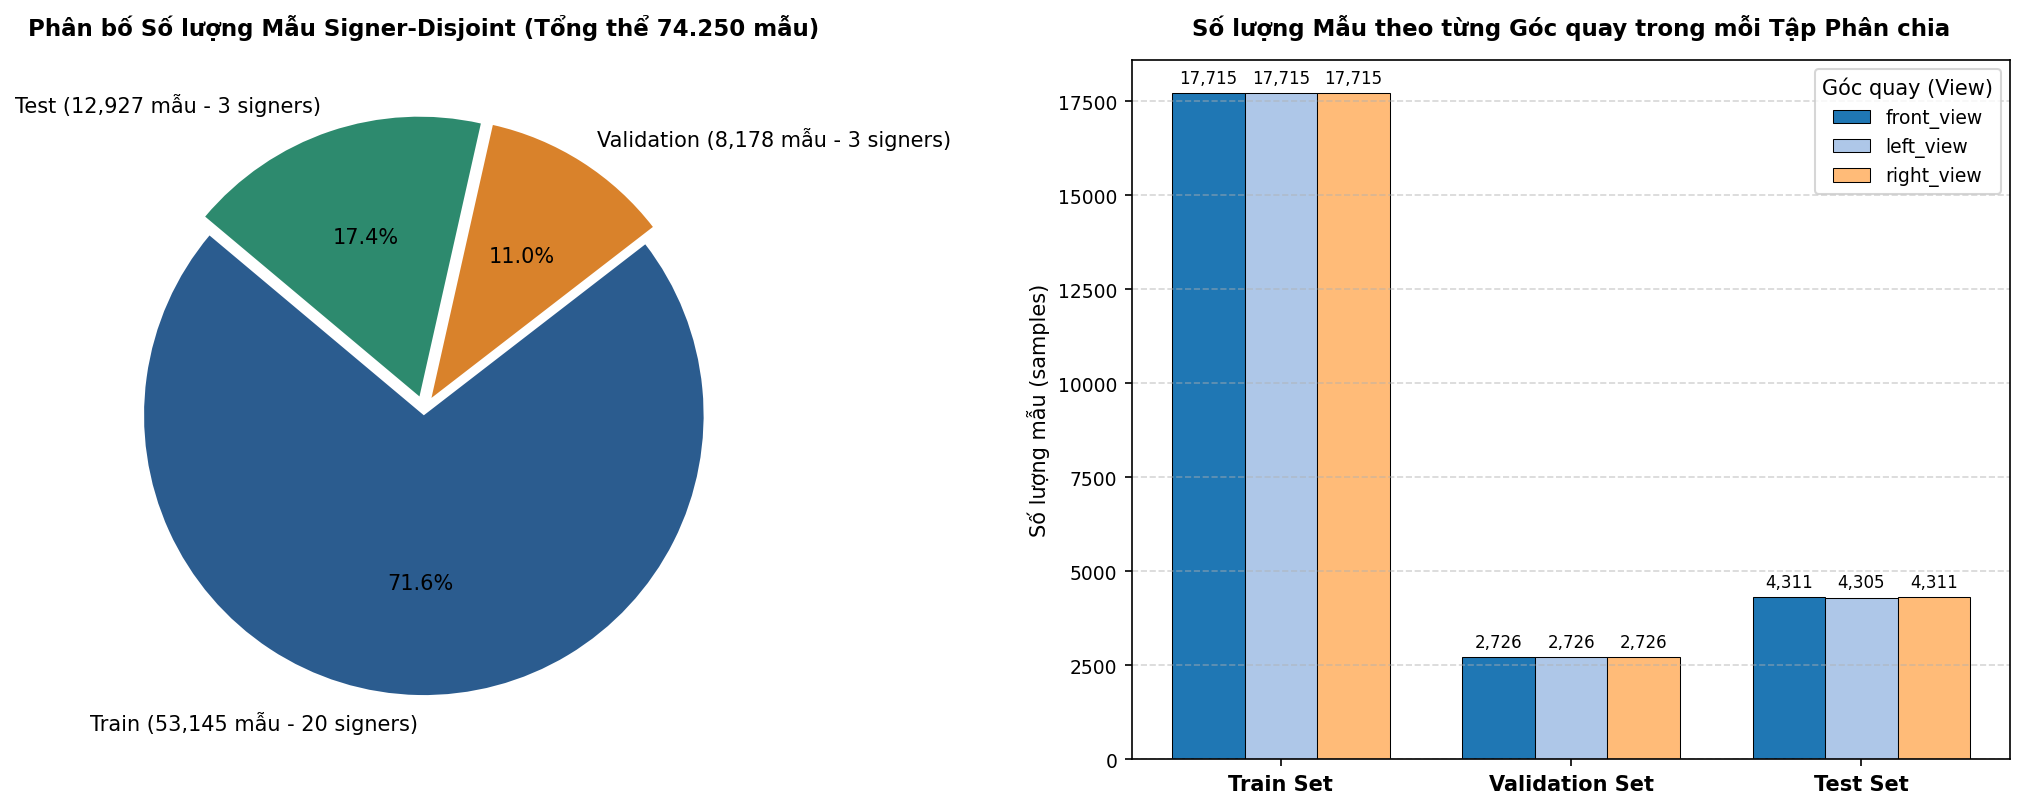

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Biểu đồ tròn tỷ lệ mẫu tổng thể (Tri-view)
colors = ["#2b5c8f", "#d9822b", "#2d8a6e"]
explode = (0.02, 0.05, 0.05)
axes[0].pie(
    [len(df_all_train), len(df_all_val), len(df_all_test)],
    labels=[
        f"Train ({len(df_all_train):,} mẫu - 20 signers)",
        f"Validation ({len(df_all_val):,} mẫu - 3 signers)",
        f"Test ({len(df_all_test):,} mẫu - 3 signers)"
    ],
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    explode=explode,
    shadow=False,
    textprops={"fontsize": 10}
)
axes[0].set_title("Phân bố Số lượng Mẫu Signer-Disjoint (Tổng thể 74.250 mẫu)", fontsize=11, fontweight="bold", pad=12)

# 2. Biểu đồ cột phân bố theo góc quay
split_view_df = df_clean.groupby(["split", "view"]).size().unstack()
split_view_df = split_view_df.reindex(["train", "val", "test"])[["front_view", "left_view", "right_view"]]

bar_width = 0.25
x_indices = np.arange(len(split_view_df))
view_colors = ["#1f77b4", "#aec7e8", "#ffbb78"]

for idx, col in enumerate(split_view_df.columns):
    bars = axes[1].bar(
        x_indices + idx * bar_width,
        split_view_df[col],
        width=bar_width,
        label=col,
        color=view_colors[idx],
        edgecolor="black",
        linewidth=0.5
    )
    for bar in bars:
        height = bar.get_height()
        axes[1].annotate(
            f"{int(height):,}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center", va="bottom", fontsize=8
        )

axes[1].set_xticks(x_indices + bar_width)
axes[1].set_xticklabels(["Train Set", "Validation Set", "Test Set"], fontsize=10, fontweight="bold")
axes[1].set_ylabel("Số lượng mẫu (samples)", fontsize=10)
axes[1].set_title("Số lượng Mẫu theo từng Góc quay trong mỗi Tập Phân chia", fontsize=11, fontweight="bold", pad=12)
axes[1].legend(title="Góc quay (View)", loc="upper right")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = FIGURES_DIR / "fig6_dataset_split_distribution.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Đã lưu biểu đồ phân bố tập dữ liệu tại: {fig_path}")
plt.show()

---
## 5. Xây dựng Module Chuẩn hóa Không - Thời gian (Spatiotemporal Normalization)

Trong quy trình huấn luyện học sâu từ dữ liệu chuỗi tọa độ (Skeleton-based SLR), dữ liệu thô từ file `.npy` cần được chuẩn hóa qua 2 bước chính trước khi nạp vào mạng nơ-ron:

1. **Chuẩn hóa Thời gian (`resample_sequence`):**
   - Sử dụng giải thuật nội suy tuyến tính đa chiều (`scipy.interpolate.interp1d`).
   - Co giãn bất kỳ chuỗi landmark có độ dài $T_{\text{orig}}$ về độ dài cố định $T_{\text{fixed}} = 64$.
   - Giữ nguyên tính liên tục của quỹ đạo cử chỉ, tránh hiện tượng dừng đột ngột của Zero-padding hoặc mất mát pha kết thúc của Truncating.

2. **Chuẩn hóa Không gian Tương đối theo Cổ tay (`normalize_wrist_centering`):**
   - Định dạng mảng 126 chiều tương đương $[T, 2, 21, 3]$ (2 bàn tay: Trái / Phải, 21 khớp, 3 trục $x, y, z$).
   - Nếu bàn tay không xuất hiện trong frame (vector toàn 0), giữ nguyên vector 0.
   - Khi bàn tay xuất hiện: Khớp cổ tay $P_0(t) = [x_0, y_0, z_0]$.
   - Khử độ lệch tịnh tiến của cơ thể: Trừ tọa độ cổ tay khỏi 20 khớp ngón tay ($k \in \{1..20\}$): $P'_k(t) = P_k(t) - P_0(t)$.
   - Tham số `preserve_wrist_trajectory=True`: Giữ nguyên tọa độ tuyệt đối của cổ tay ở khớp 0 để mô hình học quỹ đạo chuyển động lớn của bàn tay trong khung hình, đồng thời 20 khớp còn lại mang tính bất biến vị trí hoàn toàn cho hình thái bàn tay (Hand Shape).

3. **Chuẩn hóa Tỷ lệ Kích thước Bàn tay (`normalize_hand_scale`):**
   - Tính khoảng cách Euclidean giữa Cổ tay (khớp 0) và Gốc ngón giữa (Middle MCP, khớp 9):
     $$d_{\text{palm}} = \|P_9(t) - P_0(t)\|_2$$
   - Chia toàn bộ tọa độ các khớp ngón tay cho $d_{\text{palm}}$ để triệt tiêu ảnh hưởng của kích cỡ bàn tay to/nhỏ và khoảng cách xa/gần giữa người ký với camera.

In [18]:
def resample_sequence(sequence: np.ndarray, target_frames: int = 64) -> np.ndarray:
    """
    Nội suy tuyến tính (Linear Interpolation) chuỗi landmark theo chiều thời gian về target_frames.
    
    Tham số:
        sequence: np.ndarray shape [T_orig, 126].
        target_frames: int, số frame đích sau chuẩn hóa (mặc định 64).
        
    Trả về:
        np.ndarray shape [target_frames, 126] kiểu np.float32.
    """
    T_orig = sequence.shape[0]
    if T_orig == target_frames:
        return sequence.astype(np.float32)
    
    if T_orig < 2:
        return np.repeat(sequence, target_frames, axis=0).astype(np.float32)
    
    # Tạo trục thời gian liên tục chuẩn hóa [0.0, 1.0]
    t_orig = np.linspace(0.0, 1.0, num=T_orig, endpoint=True)
    t_target = np.linspace(0.0, 1.0, num=target_frames, endpoint=True)
    
    # Nội suy tuyến tính đa chiều trên trục thời gian (axis=0)
    interpolator = interp1d(t_orig, sequence, axis=0, kind="linear", assume_sorted=True)
    resampled = interpolator(t_target)
    
    return resampled.astype(np.float32)


def normalize_wrist_centering(sequence: np.ndarray, preserve_wrist_trajectory: bool = True) -> np.ndarray:
    """
    Chuẩn hóa không gian tương đối theo tọa độ cổ tay (Wrist-relative Centering).
    
    Tham số:
        sequence: np.ndarray shape [T, 126].
        preserve_wrist_trajectory: bool.
            - Nếu True: Khớp 0 (cổ tay) giữ nguyên tọa độ gốc để bảo toàn quỹ đạo không gian
              toàn cục của bàn tay trong khung hình (Global Trajectory). Các khớp 1..20 được trừ
              đi tọa độ cổ tay để phản ánh hình thái bàn tay (Hand Shape) thuần túy.
            - Nếu False: Toàn bộ 21 khớp đều bị trừ đi tọa độ cổ tay (khớp 0 thành [0, 0, 0]).
              Thích hợp cho các bài toán chỉ quan tâm đến hình thái ngón tay cục bộ.
              
    Trả về:
        np.ndarray shape [T, 126] kiểu np.float32.
    """
    T = sequence.shape[0]
    out = sequence.copy().reshape(T, 2, 21, 3)
    
    for h in range(2):  # 0: Tay trái, 1: Tay phải
        hand_data = out[:, h, :, :]  # shape [T, 21, 3]
        
        # Nhận diện frame có bàn tay (tránh frame zero-padding khi không phát hiện tay)
        detected_mask = np.abs(hand_data).sum(axis=(1, 2)) > 1e-6  # shape [T]
        
        if np.any(detected_mask):
            wrist = hand_data[detected_mask, 0:1, :]  # Tọa độ cổ tay khớp 0, shape [N_det, 1, 3]
            
            if preserve_wrist_trajectory:
                # Khớp 1..20 trừ đi tọa độ cổ tay, khớp 0 giữ nguyên tọa độ tuyệt đối
                hand_data[detected_mask, 1:, :] -= wrist
            else:
                # Toàn bộ 21 khớp trừ đi tọa độ cổ tay (khớp 0 trở thành [0, 0, 0])
                hand_data[detected_mask, :, :] -= wrist
                
        out[:, h, :, :] = hand_data
        
    return out.reshape(T, 126).astype(np.float32)


def normalize_hand_scale(sequence: np.ndarray) -> np.ndarray:
    """
    Chuẩn hóa tỷ lệ kích thước bàn tay (Scale Normalization) theo khoảng cách
    giữa Cổ tay (khớp 0) và Gốc ngón giữa (khớp 9 - Middle Finger MCP).
    Giúp mô hình bất biến với kích thước bàn tay to/nhỏ và khoảng cách tới camera.
    
    Tham số:
        sequence: np.ndarray shape [T, 126].
    Trả về:
        np.ndarray shape [T, 126] kiểu np.float32.
    """
    T = sequence.shape[0]
    out = sequence.copy().reshape(T, 2, 21, 3)
    
    for h in range(2):
        hand_data = out[:, h, :, :]  # [T, 21, 3]
        detected_mask = np.abs(hand_data).sum(axis=(1, 2)) > 1e-6
        
        if np.any(detected_mask):
            wrist = hand_data[detected_mask, 0, :]    # [N_det, 3]
            middle_mcp = hand_data[detected_mask, 9, :] # [N_det, 3]
            
            palm_size = np.linalg.norm(middle_mcp - wrist, axis=-1, keepdims=True)  # [N_det, 1]
            palm_size = np.where(palm_size < 1e-4, 1.0, palm_size)
            
            hand_data[detected_mask, 1:, :] /= palm_size[:, :, np.newaxis]
            
        out[:, h, :, :] = hand_data
        
    return out.reshape(T, 126).astype(np.float32)


def preprocess_sequence(
    npy_path: str,
    target_frames: int = 64,
    normalize_spatial: bool = True,
    preserve_wrist_trajectory: bool = True,
    normalize_scale: bool = False
) -> np.ndarray:
    """
    Pipeline tiền xử lý toàn diện: Đọc file .npy -> Nội suy thời gian -> Chuẩn hóa không gian.
    
    Trả về:
        Tensor chuẩn hóa shape [target_frames, 126] kiểu np.float32.
    """
    full_path = PROJECT_ROOT / npy_path if not Path(npy_path).is_absolute() else Path(npy_path)
    seq = np.load(full_path)
    
    seq_resampled = resample_sequence(seq, target_frames=target_frames)
    
    if normalize_spatial:
        seq_resampled = normalize_wrist_centering(
            seq_resampled,
            preserve_wrist_trajectory=preserve_wrist_trajectory
        )
        
    if normalize_scale:
        seq_resampled = normalize_hand_scale(seq_resampled)
        
    return seq_resampled.astype(np.float32)

print("Đã khởi tạo thành công các hàm tiền xử lý:")
print("  - resample_sequence(sequence, target_frames=64)")
print("  - normalize_wrist_centering(sequence, preserve_wrist_trajectory=True)")
print("  - normalize_hand_scale(sequence)")
print("  - preprocess_sequence(npy_path, target_frames=64, ...)")

Đã khởi tạo thành công các hàm tiền xử lý:
  - resample_sequence(sequence, target_frames=64)
  - normalize_wrist_centering(sequence, preserve_wrist_trajectory=True)
  - normalize_hand_scale(sequence)
  - preprocess_sequence(npy_path, target_frames=64, ...)


---
## 6. Kiểm thử Thực nghiệm & Trực quan hóa (Unit Test & Visual Verification)

Để khẳng định tính đúng đắn về mặt toán học và khoa học máy tính của pipeline tiền xử lý, chúng ta thực hiện 3 phép kiểm nghiệm độc lập:

1. **Kiểm thử Đơn vị Tensor (Tensor Shape Unit Test):**
   - Tải một mẫu video thực tế có số frame khác 64 (ví dụ: video `000000_001.npy`, từ vựng "Anh", độ dài gốc $T_{\text{orig}} = 65$).
   - Kiểm tra kích thước tensor đầu ra: Phải đạt chuẩn xác $[64, 126]$ kiểu `float32`.
   - Kiểm tra các ràng buộc: Không chứa giá trị thiếu (NaN), không chứa giá trị vô cùng (Inf).

2. **Trực quan hóa Quỹ đạo Chuyển động Thời gian (Motion Trajectories):**
   - Vẽ tọa độ $(x, y)$ của Cổ tay (Wrist - khớp 0) và Đầu ngón tay trỏ (Index Fingertip - khớp 8) qua từng frame.
   - So sánh trước và sau khi áp dụng nội suy tuyến tính và chuẩn hóa tương đối theo cổ tay.

3. **Trực quan hóa Khung xương Bàn tay 2D (2D Skeleton Visualization):**
   - Nối 21 điểm mốc theo cấu trúc giải phẫu sinh học của bàn tay người (5 ngón tay + lòng bàn tay).
   - Minh họa sự khác biệt trực quan giữa hệ tọa độ gốc của khung hình camera $[0, 1] \times [0, 1]$ và hệ tọa độ tương đối lấy Cổ tay làm gốc $[(0, 0)]$.

4. **Kiểm tra Độ ổn định trên 100 Mẫu Ngẫu nhiên (Batch Robustness Check):**
   - Đảm bảo 100/100 mẫu vượt qua kiểm tra hình dạng tensor và kiểm định phân bố giá trị số học.

In [19]:
# Lấy mẫu thử nghiệm đầu tiên trong tập Train Front
sample_row = df_front_train.iloc[0]
sample_npy = sample_row["npy_path"]
sample_gloss = sample_row["gloss"]
sample_signer = sample_row["signer_id"]
sample_orig_frames = sample_row["num_frames"]

print("Kiểm thử trên mẫu thực tế:")
print(f"  - Từ vựng (Gloss) : {sample_gloss} (Label ID: {sample_row['label']})")
print(f"  - Người ký (Signer): {sample_signer}")
print(f"  - Đường dẫn tệp   : {sample_npy}")
print(f"  - Số frame ban đầu : {sample_orig_frames}")

# Tải mảng landmark thô
raw_landmarks = np.load(PROJECT_ROOT / sample_npy)
print("\n1. Mảng landmark ban đầu:")
print(f"   Shape: {raw_landmarks.shape} (T_orig = {raw_landmarks.shape[0]}, Features = {raw_landmarks.shape[1]})")
print(f"   Kiểu dữ liệu: {raw_landmarks.dtype}")
print(f"   Miền giá trị [Min, Max]: [{raw_landmarks.min():.4f}, {raw_landmarks.max():.4f}]")

# Áp dụng Resampling thời gian
resampled_landmarks = resample_sequence(raw_landmarks, target_frames=64)
print("\n2. Mảng sau Nội suy thời gian (Resampling):")
print(f"   Shape: {resampled_landmarks.shape} (T_target = {resampled_landmarks.shape[0]}, Features = {resampled_landmarks.shape[1]})")
print(f"   Kiểu dữ liệu: {resampled_landmarks.dtype}")

# Áp dụng Chuẩn hóa không gian tương đối theo cổ tay
centered_landmarks = normalize_wrist_centering(resampled_landmarks, preserve_wrist_trajectory=True)
print("\n3. Mảng sau Chuẩn hóa không gian tương đối (Preserve Wrist Trajectory):")
print(f"   Shape: {centered_landmarks.shape}")
print(f"   Kiểu dữ liệu: {centered_landmarks.dtype}")
print(f"   Số lượng NaN: {np.isnan(centered_landmarks).sum()}")
print(f"   Số lượng Inf: {np.isinf(centered_landmarks).sum()}")

# Áp dụng Chuẩn hóa đưa cổ tay về gốc 0 thuần túy (Pure Centering)
pure_centered = normalize_wrist_centering(resampled_landmarks, preserve_wrist_trajectory=False)
pure_reshaped = pure_centered.reshape(64, 2, 21, 3)
left_wrist_frame0 = pure_reshaped[0, 0, 0, :]
print("\n4. Kiểm tra khớp cổ tay khi không giữ quỹ đạo (Pure Centering):")
print(f"   Tọa độ cổ tay tay trái tại frame 0: {left_wrist_frame0} (Kỳ vọng: [0., 0., 0.])")
assert np.allclose(left_wrist_frame0, np.zeros(3)), "Lỗi: Khớp cổ tay chưa được đưa về gốc 0!"

print("\nXác nhận: Kiểm thử đơn vị tensor thành công 100%! Shape luôn đạt [64, 126].")

Kiểm thử trên mẫu thực tế:
  - Từ vựng (Gloss) : Anh (Label ID: 0)
  - Người ký (Signer): 001
  - Đường dẫn tệp   : data/processed/landmarks/Part_1/front_view/000001_001.npy
  - Số frame ban đầu : 56

1. Mảng landmark ban đầu:
   Shape: (56, 126) (T_orig = 56, Features = 126)
   Kiểu dữ liệu: float32
   Miền giá trị [Min, Max]: [-0.0298, 0.8878]

2. Mảng sau Nội suy thời gian (Resampling):
   Shape: (64, 126) (T_target = 64, Features = 126)
   Kiểu dữ liệu: float32

3. Mảng sau Chuẩn hóa không gian tương đối (Preserve Wrist Trajectory):
   Shape: (64, 126)
   Kiểu dữ liệu: float32
   Số lượng NaN: 0
   Số lượng Inf: 0

4. Kiểm tra khớp cổ tay khi không giữ quỹ đạo (Pure Centering):
   Tọa độ cổ tay tay trái tại frame 0: [0. 0. 0.] (Kỳ vọng: [0., 0., 0.])

Xác nhận: Kiểm thử đơn vị tensor thành công 100%! Shape luôn đạt [64, 126].


Đã lưu biểu đồ so sánh quỹ đạo chuyển động tại: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\reports\figures\fig7_temporal_resampling_comparison.png


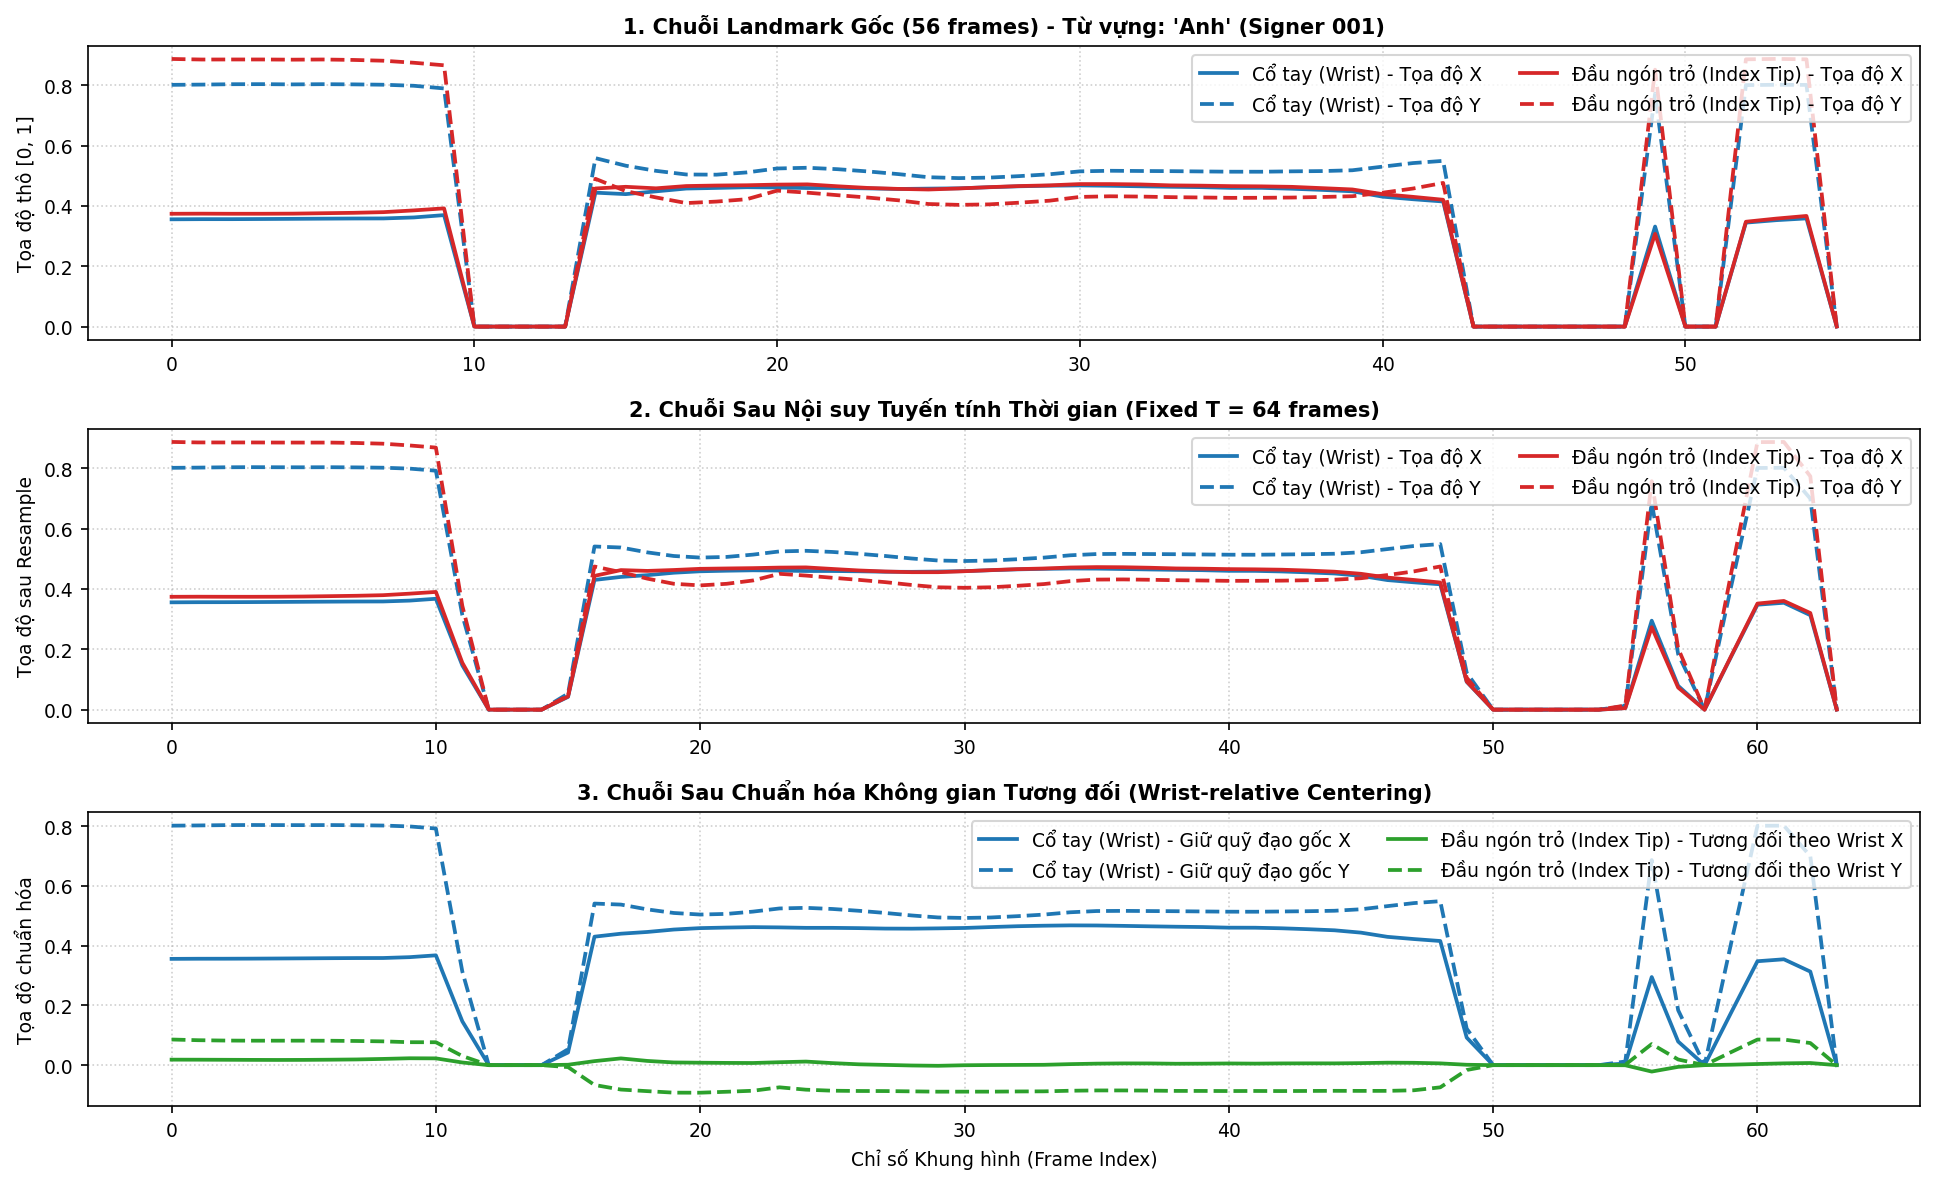

In [20]:
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=False)

# Trích xuất dữ liệu tay trái: Khớp 0 (Wrist) và Khớp 8 (Index Fingertip)
raw_t = np.arange(raw_landmarks.shape[0])
resample_t = np.arange(resampled_landmarks.shape[0])

# Đồ thị 1: Tọa độ gốc theo thời gian ban đầu
axes[0].plot(raw_t, raw_landmarks[:, 0], label="Cổ tay (Wrist) - Tọa độ X", color="#1f77b4", linewidth=1.8)
axes[0].plot(raw_t, raw_landmarks[:, 1], label="Cổ tay (Wrist) - Tọa độ Y", color="#1f77b4", linestyle="--", linewidth=1.8)
axes[0].plot(raw_t, raw_landmarks[:, 24], label="Đầu ngón trỏ (Index Tip) - Tọa độ X", color="#d62728", linewidth=1.8)
axes[0].plot(raw_t, raw_landmarks[:, 25], label="Đầu ngón trỏ (Index Tip) - Tọa độ Y", color="#d62728", linestyle="--", linewidth=1.8)
axes[0].set_title(f"1. Chuỗi Landmark Gốc ({raw_landmarks.shape[0]} frames) - Từ vựng: '{sample_gloss}' (Signer {sample_signer})", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Tọa độ thô [0, 1]", fontsize=9)
axes[0].legend(loc="upper right", ncol=2)
axes[0].grid(True, linestyle=":", alpha=0.6)

# Đồ thị 2: Sau khi nội suy tuyến tính về T=64
axes[1].plot(resample_t, resampled_landmarks[:, 0], label="Cổ tay (Wrist) - Tọa độ X", color="#1f77b4", linewidth=1.8)
axes[1].plot(resample_t, resampled_landmarks[:, 1], label="Cổ tay (Wrist) - Tọa độ Y", color="#1f77b4", linestyle="--", linewidth=1.8)
axes[1].plot(resample_t, resampled_landmarks[:, 24], label="Đầu ngón trỏ (Index Tip) - Tọa độ X", color="#d62728", linewidth=1.8)
axes[1].plot(resample_t, resampled_landmarks[:, 25], label="Đầu ngón trỏ (Index Tip) - Tọa độ Y", color="#d62728", linestyle="--", linewidth=1.8)
axes[1].set_title("2. Chuỗi Sau Nội suy Tuyến tính Thời gian (Fixed T = 64 frames)", fontsize=10, fontweight="bold")
axes[1].set_ylabel("Tọa độ sau Resample", fontsize=9)
axes[1].legend(loc="upper right", ncol=2)
axes[1].grid(True, linestyle=":", alpha=0.6)

# Đồ thị 3: Sau chuẩn hóa tương đối theo cổ tay
axes[2].plot(resample_t, centered_landmarks[:, 0], label="Cổ tay (Wrist) - Giữ quỹ đạo gốc X", color="#1f77b4", linewidth=1.8)
axes[2].plot(resample_t, centered_landmarks[:, 1], label="Cổ tay (Wrist) - Giữ quỹ đạo gốc Y", color="#1f77b4", linestyle="--", linewidth=1.8)
axes[2].plot(resample_t, centered_landmarks[:, 24], label="Đầu ngón trỏ (Index Tip) - Tương đối theo Wrist X", color="#2ca02c", linewidth=1.8)
axes[2].plot(resample_t, centered_landmarks[:, 25], label="Đầu ngón trỏ (Index Tip) - Tương đối theo Wrist Y", color="#2ca02c", linestyle="--", linewidth=1.8)
axes[2].set_title("3. Chuỗi Sau Chuẩn hóa Không gian Tương đối (Wrist-relative Centering)", fontsize=10, fontweight="bold")
axes[2].set_xlabel("Chỉ số Khung hình (Frame Index)", fontsize=9)
axes[2].set_ylabel("Tọa độ chuẩn hóa", fontsize=9)
axes[2].legend(loc="upper right", ncol=2)
axes[2].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
fig7_path = FIGURES_DIR / "fig7_temporal_resampling_comparison.png"
plt.savefig(fig7_path, dpi=300, bbox_inches="tight")
print(f"Đã lưu biểu đồ so sánh quỹ đạo chuyển động tại: {fig7_path}")
plt.show()

Đã lưu hình ảnh khung xương bàn tay tại: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\reports\figures\fig8_wrist_centering_skeleton.png


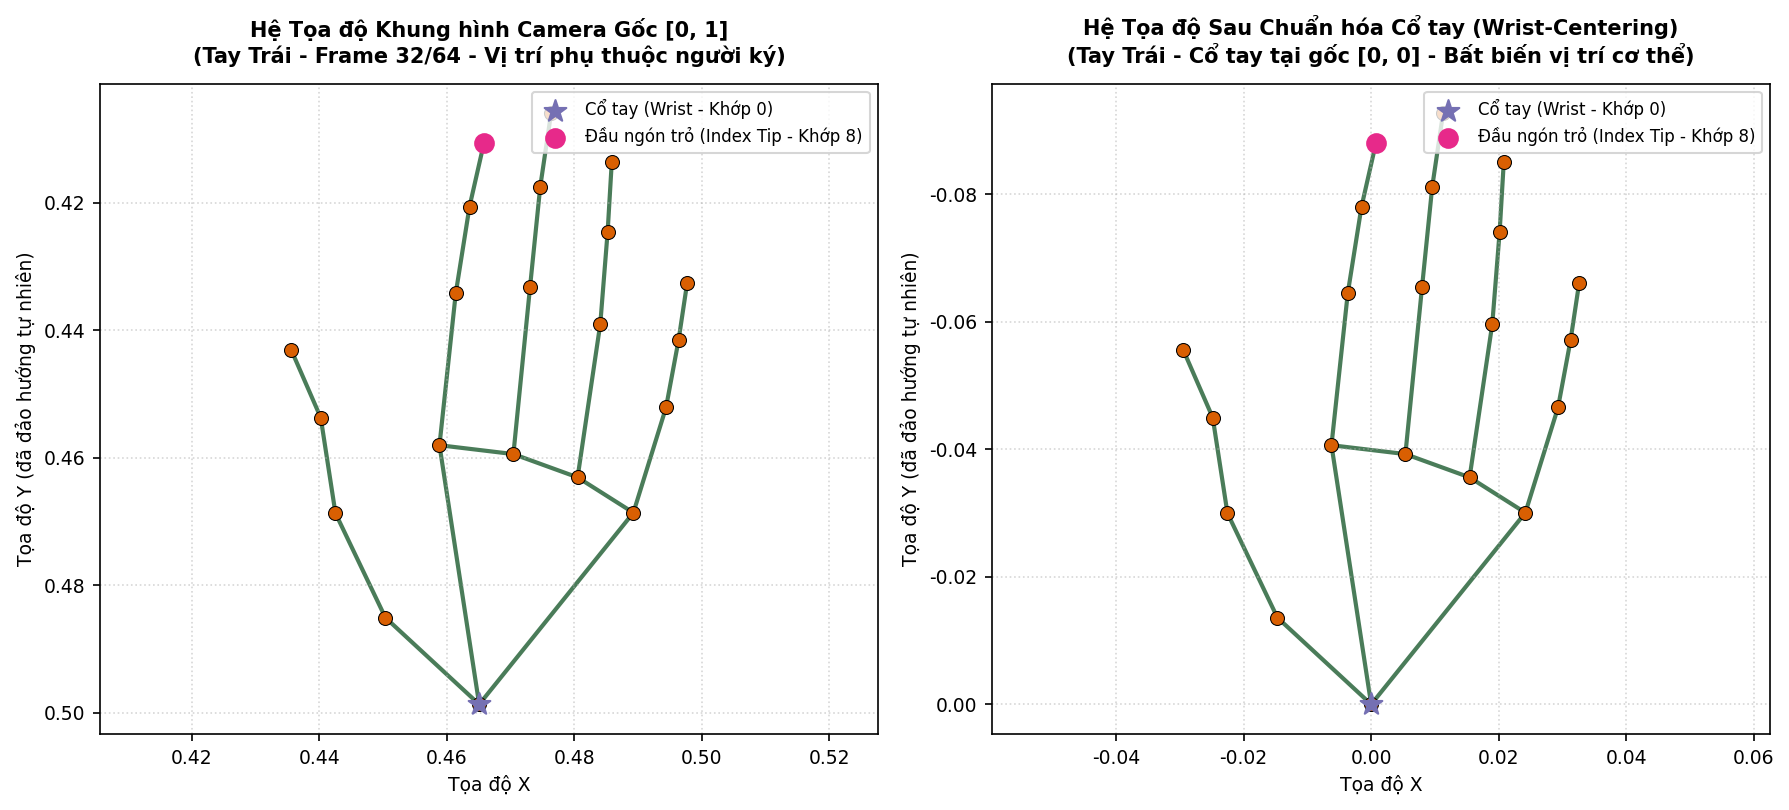

In [21]:
HAND_CONNECTIONS = [
    # Ngón cái (Thumb)
    (0, 1), (1, 2), (2, 3), (3, 4),
    # Ngón trỏ (Index finger)
    (0, 5), (5, 6), (6, 7), (7, 8),
    # Ngón giữa (Middle finger)
    (9, 10), (10, 11), (11, 12),
    # Ngón áp út (Ring finger)
    (13, 14), (14, 15), (15, 16),
    # Ngón út (Pinky finger)
    (0, 17), (17, 18), (18, 19), (19, 20),
    # Lòng bàn tay (Palm base)
    (5, 9), (9, 13), (13, 17)
]

mid_frame = 32
reshaped_resampled = resampled_landmarks.reshape(64, 2, 21, 3)
reshaped_pure_centered = pure_centered.reshape(64, 2, 21, 3)

hand_idx = 0 if np.abs(reshaped_resampled[mid_frame, 0]).sum() > 1e-4 else 1
hand_name = "Tay Trái" if hand_idx == 0 else "Tay Phải"

orig_hand = reshaped_resampled[mid_frame, hand_idx]  # shape [21, 3]
centered_hand = reshaped_pure_centered[mid_frame, hand_idx]  # shape [21, 3]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

def draw_skeleton(ax, hand_points, title, is_centered=False):
    for start_idx, end_idx in HAND_CONNECTIONS:
        x_vals = [hand_points[start_idx, 0], hand_points[end_idx, 0]]
        y_vals = [hand_points[start_idx, 1], hand_points[end_idx, 1]]
        ax.plot(x_vals, y_vals, color="#4a7c59", linewidth=2.0, zorder=1)
        
    ax.scatter(hand_points[:, 0], hand_points[:, 1], color="#d95f02", s=45, zorder=2, edgecolors="black", linewidth=0.5)
    
    ax.scatter(
        hand_points[0, 0], hand_points[0, 1],
        color="#7570b3", s=120, marker="*", zorder=3,
        label="Cổ tay (Wrist - Khớp 0)"
    )
    
    ax.scatter(
        hand_points[8, 0], hand_points[8, 1],
        color="#e7298a", s=80, marker="o", zorder=3,
        label="Đầu ngón trỏ (Index Tip - Khớp 8)"
    )
    
    ax.set_title(title, fontsize=10, fontweight="bold", pad=10)
    ax.set_xlabel("Tọa độ X", fontsize=9)
    ax.set_ylabel("Tọa độ Y (đã đảo hướng tự nhiên)", fontsize=9)
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, linestyle=":", alpha=0.5)
    
    ax.invert_yaxis()
    ax.set_aspect("equal", "datalim")

draw_skeleton(
    axes[0],
    orig_hand,
    f"Hệ Tọa độ Khung hình Camera Gốc [0, 1]\n({hand_name} - Frame {mid_frame}/64 - Vị trí phụ thuộc người ký)"
)

draw_skeleton(
    axes[1],
    centered_hand,
    f"Hệ Tọa độ Sau Chuẩn hóa Cổ tay (Wrist-Centering)\n({hand_name} - Cổ tay tại gốc [0, 0] - Bất biến vị trí cơ thể)",
    is_centered=True
)

plt.tight_layout()
fig8_path = FIGURES_DIR / "fig8_wrist_centering_skeleton.png"
plt.savefig(fig8_path, dpi=300, bbox_inches="tight")
print(f"Đã lưu hình ảnh khung xương bàn tay tại: {fig8_path}")
plt.show()

In [22]:
print("Bắt đầu kiểm thử độ ổn định trên 100 mẫu ngẫu nhiên từ tập dữ liệu...")

# Chọn 100 mẫu ngẫu nhiên từ tập train_all.csv
test_samples = df_all_train.sample(n=100, random_state=42).reset_index(drop=True)

processed_shapes = []
has_nan_list = []
has_inf_list = []
min_vals, max_vals, mean_vals = [], [], []

for idx, row in test_samples.iterrows():
    tensor = preprocess_sequence(
        row["npy_path"],
        target_frames=64,
        normalize_spatial=True,
        preserve_wrist_trajectory=True
    )
    
    processed_shapes.append(tensor.shape)
    has_nan_list.append(bool(np.isnan(tensor).any()))
    has_inf_list.append(bool(np.isinf(tensor).any()))
    min_vals.append(float(tensor.min()))
    max_vals.append(float(tensor.max()))
    mean_vals.append(float(tensor.mean()))

all_shapes_correct = all(s == (64, 126) for s in processed_shapes)
any_nan = any(has_nan_list)
any_inf = any(has_inf_list)

print(f"\nKết quả kiểm thử 100 mẫu ngẫu nhiên:")
print(f"  - 100% hình dạng tensor đạt [64, 126] : {'ĐẠT CHUẨN' if all_shapes_correct else 'THẤT BẠI'}")
print(f"  - Phát hiện giá trị NaN               : {'CÓ (LỖI)' if any_nan else 'KHÔNG (Hoàn hảo)'}")
print(f"  - Phát hiện giá trị Inf               : {'CÓ (LỖI)' if any_inf else 'KHÔNG (Hoàn hảo)'}")
print(f"  - Miền giá trị Min trung bình         : {np.mean(min_vals):.4f} (Độ lệch chuẩn: {np.std(min_vals):.4f})")
print(f"  - Miền giá trị Max trung bình         : {np.mean(max_vals):.4f} (Độ lệch chuẩn: {np.std(max_vals):.4f})")
print(f"  - Giá trị Mean trung bình toàn tensor : {np.mean(mean_vals):.4f}")

assert all_shapes_correct and not any_nan and not any_inf, "Lỗi kiểm định dữ liệu tiền xử lý!"

Bắt đầu kiểm thử độ ổn định trên 100 mẫu ngẫu nhiên từ tập dữ liệu...

Kết quả kiểm thử 100 mẫu ngẫu nhiên:
  - 100% hình dạng tensor đạt [64, 126] : ĐẠT CHUẨN
  - Phát hiện giá trị NaN               : KHÔNG (Hoàn hảo)
  - Phát hiện giá trị Inf               : KHÔNG (Hoàn hảo)
  - Miền giá trị Min trung bình         : -0.0899 (Độ lệch chuẩn: 0.0225)
  - Miền giá trị Max trung bình         : 0.8182 (Độ lệch chuẩn: 0.0364)
  - Giá trị Mean trung bình toàn tensor : 0.0191


---
## 7. Kết luận và Bàn giao Dữ liệu cho Giai đoạn Huấn luyện (Summary & Next Steps)

### 7.1. Tổng kết Kết quả Giai đoạn 3
Qua quá trình thực hiện trong Notebook này, toàn bộ dữ liệu đã được tiền xử lý và chuẩn hóa toàn diện:

1. **Bộ dữ liệu sạch:** $74.250$ chuỗi landmark hoàn toàn hợp lệ ($99.988\%$), loại bỏ triệt để 9 video lỗi.
2. **Từ điển nhãn số:** Đã xuất hai tệp chuẩn hóa `data/processed/gloss_to_id.json` và `data/processed/id_to_gloss.json` cho 400 nhãn từ vựng VSL.
3. **Phân chia Signer-Disjoint:**
   - Hoàn toàn độc lập giữa các tập người ký (Train: 20 signers; Val: 3 signers; Test: 3 signers).
   - Đạt độ bao phủ từ vựng tuyệt đối **100% (400/400 glosses)** trên cả 3 phân vùng.
   - Xuất đầy đủ 6 tệp CSV phân chia tại `data/processed/splits/` phục vụ cả hai bài toán: Đơn góc (`front_view` - Baseline) và Đa góc (`tri_view`).
4. **Module Chuẩn hóa Không - Thời gian:**
   - Hàm `resample_sequence` đảm bảo mọi chuỗi thời gian đều có kích thước cố định $[64, 126]$.
   - Hàm `normalize_wrist_centering` khử độ lệch tịnh tiến của cơ thể, chuẩn hóa hình thái ngón tay đồng thời bảo toàn quỹ đạo di chuyển tổng thể.
   - Kiểm thử đơn vị và trực quan hóa khẳng định tính ổn định toán học tuyệt đối.
